In [1]:
%pip install pandas numpy scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

In [3]:
df = pd.read_csv("Salary_Data.csv")

display(df.head())
print("satir ve sutun sayisi:", df.shape)

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


satir ve sutun sayisi: (6704, 6)


In [4]:
print("sutunlardaki eksik veri sayisi:")
display(df.isnull().sum())

df = df.dropna().copy()

print("eksik veriler temizlendikten sonra satir sayisi:", len(df))

sutunlardaki eksik veri sayisi:


Age                    2
Gender                 2
Education Level        3
Job Title              2
Years of Experience    3
Salary                 5
dtype: int64

eksik veriler temizlendikten sonra satir sayisi: 6698


In [5]:
display(df.describe().round(2))

,Age,Years of Experience,Salary
count,6698.00,6698.00,6698.00
mean,33.62,8.10,115329.25
std,7.62,6.06,52789.79
min,21.00,0.00,350.00
25%,28.00,3.00,70000.00
50%,32.00,7.00,115000.00
75%,38.00,12.00,160000.00
max,62.00,34.00,250000.00


In [6]:
display(df.describe(include="object").T)

C:\Users\merye\AppData\Local\Temp\ipykernel_12676\2515387694.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object").T)


,count,unique,top,freq
Gender,6698,3,Male,3671
Education Level,6698,7,Bachelor's Degree,2265
Job Title,6698,191,Software Engineer,518


In [7]:
education_salary = (
    df.groupby("Education Level")["Salary"]
    .agg(["count", "mean", "median"])
    .round(0)
    .rename(columns={
        "count": "Kişi Sayısı",
        "mean": "Ortalama Maaş",
        "median": "Ortanca Maaş"
    })
)

display(education_salary)

,Kişi Sayısı,Ortalama Maaş,Ortanca Maaş
Education Level,,,
Bachelor's,756,124768.0,130000.0
Bachelor's Degree,2265,85175.0,75000.0
High School,448,36707.0,30000.0
Master's,288,157604.0,177500.0
Master's Degree,1572,125075.0,122000.0
PhD,1368,165685.0,170000.0
phD,1,120000.0,120000.0


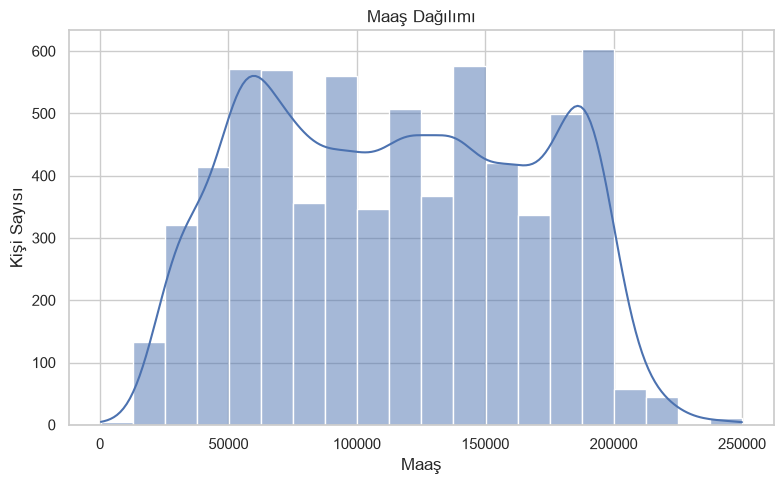

In [8]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Salary", bins=20, kde=True)
plt.title("Maaş Dağılımı")
plt.xlabel("Maaş")
plt.ylabel("Kişi Sayısı")
plt.tight_layout()
plt.show()

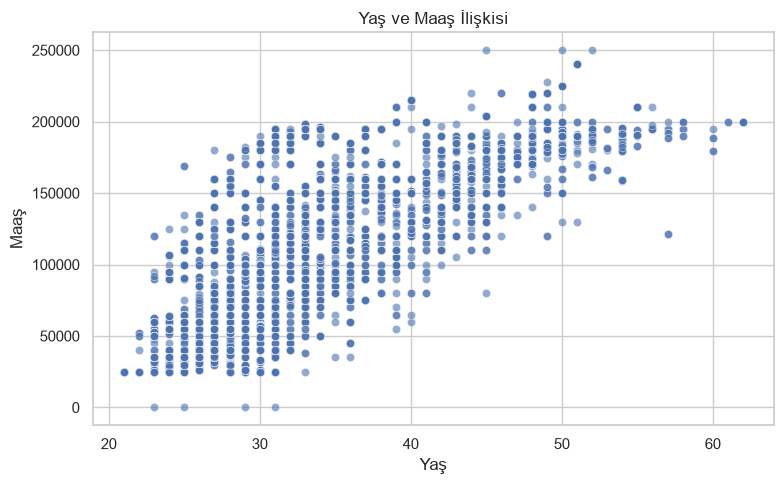

In [9]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Age", y="Salary", alpha=0.6)
plt.title("Yaş ve Maaş İlişkisi")
plt.xlabel("Yaş")
plt.ylabel("Maaş")
plt.tight_layout()
plt.show()

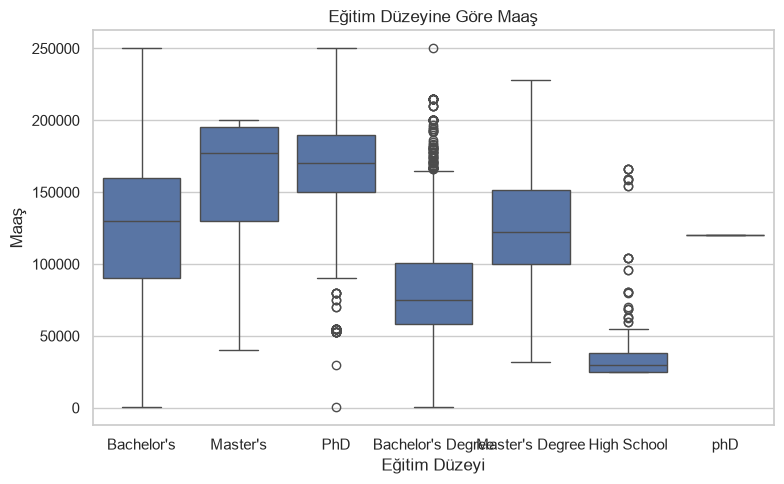

In [ ]:
plt.figure(figsize=(12, 6))
ax = sns.boxplot(data=df, x="Education Level", y="Salary")

ax.set_title("Eğitim Düzeyine Göre Maaş")
ax.set_xlabel("Eğitim Düzeyi")
ax.set_ylabel("Maaş")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

,Age,Years of Experience,Salary
Age,1.00,0.94,0.73
Years of Experience,0.94,1.00,0.81
Salary,0.73,0.81,1.00


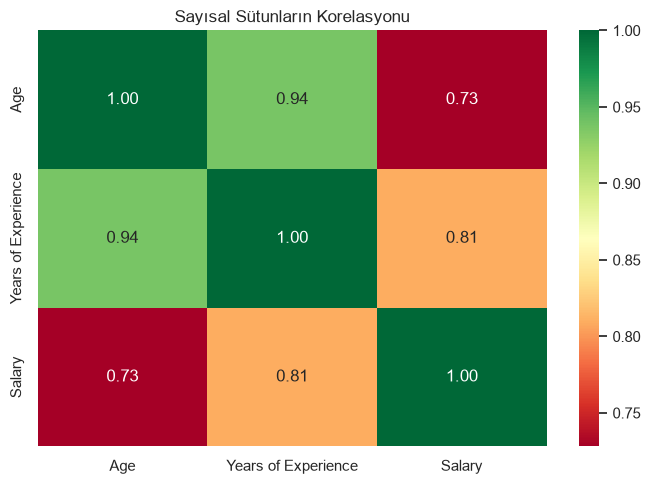

In [11]:
numeric_corr = df.select_dtypes(include="number").corr()

display(numeric_corr.round(2))

plt.figure(figsize=(7, 5))
sns.heatmap(numeric_corr, annot=True, cmap="RdYlGn", fmt=".2f")
plt.title("Sayısal Sütunların Korelasyonu")
plt.tight_layout()
plt.show()

In [12]:
X = df.drop(columns=["Salary"])
y = df["Salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Eğitim verisi:", X_train.shape)
print("Test verisi:", X_test.shape)

Eğitim verisi: (5358, 5)
Test verisi: (1340, 5)


In [13]:
num_cols = ["Age", "Years of Experience"]
cat_cols = ["Gender", "Education Level", "Job Title"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ]
)

In [14]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        random_state=42,
        n_estimators=200
    )
}

results = []
predictions = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocess", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values("R2", ascending=False)
display(results_df.round(2))

,Model,MAE,RMSE,R2
2,Random Forest,2690.32,6846.62,0.98
0,Linear Regression,13265.84,18911.12,0.87
1,Ridge,13547.42,19008.88,0.87
